<a href="https://colab.research.google.com/github/tustus1022-ui/esaa/blob/main/ESAA_OB_WEEK10_transcription2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<딥러닝 파이토치 교과서> 5장 p.200-229 필사

## **5.3 전이 학습**
**전이 학습의 개념**
- 합성곱 신경망 기반 딥러닝 모델을 제대로 훈련하려면 많은 데이터가 필요하지만, 큰 데이터셋을 확보하려면 많은 돈과 시간이 듦
- 이 문제를 해결한 것이 **전이 학습(transfer learning)**
    - 이미지넷(ImageNet)처럼 아주 큰 데이터셋으로 훈련된 모델의 가중치를 가져와, 해결하려는 과제에 맞게 보정해서 사용하는 것
    - 이미지넷: 영상 인식 기술의 성능을 평가하는 대표 이미지 데이터셋. 클래스 2만 개 이상, 이미지 총 1,419만 7,122장
- **사전 훈련된 모델(네트워크)**: 아주 큰 데이터셋으로 미리 훈련된 모델
- 결과적으로 비교적 적은 데이터로도 원하는 과제를 해결할 수 있음
- 흐름: 문제 A 해결 → 문제 A를 해결하며 얻은 지식과 경험 → (전이 학습) → 문제 B에 적용
- 전이 학습 방법: **특성 추출 기법, 미세 조정 기법**

### **5.3.1 특성 추출 기법**
**특성 추출(feature extractor)의 개념**
- ImageNet으로 사전 훈련된 모델을 가져온 뒤, 마지막 완전연결층 부분만 새로 만드는 방법
- 학습할 때는 이미지의 카테고리를 결정하는 마지막 완전연결층만 학습하고, 나머지 계층은 학습되지 않도록 함
- 이미지 분류를 위한 두 부분
    - 합성곱층: 합성곱층과 풀링층으로 구성
    - 데이터 분류기(완전연결층): 추출된 특성을 입력받아 최종적으로 이미지의 클래스를 분류하는 부분
- 사전 훈련된 네트워크의 합성곱층(가중치 고정)에 새로운 데이터를 통과시키고, 그 출력을 데이터 분류기에서 훈련함
- 사용 가능한 이미지 분류 모델: Xception, Inception V3, ResNet50, VGG16, VGG19, MobileNet

**OpenCV**
- Open Source Computer Vision Library의 약어로, 오픈 소스 컴퓨터 비전 라이브러리
- OpenCV-Python을 설치하면 파이썬에서 사용할 수 있음
- 함께 쓰는 패키지
    - torchvision: 컴퓨터 비전 용도의 패키지
    - torchvision.transforms: 데이터 전처리용 패키지
    - torchvision.models: 다양한 파이토치 네트워크를 쓸 수 있게 해 주는 패키지

In [3]:
# 라이브러리 호출
import os
import time
import copy
import glob
import cv2
import shutil

import torch
import torchvision # 컴퓨터 비전 용도의 패키지
import torchvision.transforms as transforms # 전처리 위해 사용되는 패키지
import torchvision.models as models # 다양한 파이토치 네트워크를 사용하게 하는 패키지
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader

import matplotlib.pyplot as plt

**이미지 데이터 전처리**

**transforms** : 이미지 데이터를 모델의 입력으로 쓸 수 있게 변환함
- Resize: 이미지 크기를 조정함(예: 256×256)
- RandomResizedCrop: 이미지를 랜덤한 크기와 비율로 자름
    - Resize와 RandomResizedCrop의 차이
        - Resize는 합성곱층을 통과할 수 있도록 이미지 크기를 맞추는 전처리 과정
        - RandomResizedCrop은 데이터 확장(augmentation) 용도. 이미지를 랜덤한 비율로 자른 뒤 크기를 조정함
- RandomHorizontalFlip: 이미지를 랜덤하게 수평으로 뒤집음
- ToTensor: 이미지 데이터를 텐서로 변환함

**datasets.ImageFolder** : 데이터로더가 데이터를 불러올 대상(경로)과 방법(전처리)을 정의함
- 첫 번째 파라미터: 불러올 데이터가 있는 경로
- transform: 이미지 데이터의 전처리 방법

**DataLoader**: 앞에서 정의한 ImageFolder를 할당해 데이터를 불러오는 부분
- 첫 번째 파라미터: 데이터셋
- batch_size: 한 번에 불러올 데이터 양
- num_workers: 데이터를 불러올 때 사용할 하위 프로세스 수. 너무 많이 설정하면 오류나 메모리 부족이 생길 수 있음
- shuffle: True면 데이터를 무작위로 섞어서 불러옴

**사용 데이터**
- 개와 고양이 이미지(Kaggle dogs-vs-cats). 전체를 쓰면 CPU에 과부하가 생겨 일부만 사용
- 훈련 데이터 385개

**RandomResizedCrop 자세히 보기**
- mxnet: 카네기 멜론 대학과 워싱턴 대학에서 시작한 딥러닝 오픈 소스 라이브러리. 파이썬, 줄리아, R, 매트랩, 스칼라 등 다양한 인터페이스를 지원하고 GPU 환경에서 성능이 뛰어남
- mxnet 설치 뒤 넘파이 버전 호환성 오류가 날 수 있음 → 호환되는 넘파이 버전으로 재설치한 뒤 명령어를 다시 실행하면 정상 설치됨
- 다양한 샘플을 얻기 위해 데이터 확장을 여러 번 적용함
- 파라미터
    - size: 출력할 크기(예: 200×200)
    - scale: 면적 비율을 0.1~1(10~100%) 범위에서 무작위로 자름
    - ratio: 너비와 높이의 비율을 0.5~2 범위에서 무작위로 조절함
- 즉, ratio로 너비·높이 비율을 조절하고 → scale로 자른 뒤 → 최종적으로 size 크기로 맞춤

In [7]:
# 교재 깃허브에서 5장 데이터 폴더만 내려받기 (약 32MB)
!git clone --depth 1 --filter=blob:none --sparse https://github.com/gilbutITbook/080289.git
%cd /content/080289
!git sparse-checkout set chap05/data
%cd /content/080289/chap05
!ls ../chap05/data/catanddog

Cloning into '080289'...
remote: Enumerating objects: 51, done.
remote: Counting objects: 100% (51/51), done.
remote: Compressing objects: 100% (47/47), done.
remote: Total 51 (delta 2), reused 42 (delta 2), pack-reused 0 (from 0)
Receiving objects: 100% (51/51), 57.21 KiB | 5.72 MiB/s, done.
Resolving deltas: 100% (2/2), done.
remote: Enumerating objects: 1, done.
remote: Counting objects: 100% (1/1), done.
remote: Total 1 (delta 0), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (1/1), 1.04 KiB | 1.04 MiB/s, done.
/content/080289
remote: Enumerating objects: 489, done.
remote: Counting objects: 100% (489/489), done.
remote: Compressing objects: 100% (489/489), done.
remote: Total 489 (delta 0), reused 488 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (489/489), 33.70 MiB | 25.41 MiB/s, done.
Updating files: 100% (489/489), done.
/content/080289/chap05
test  train


In [8]:
# 이미지 데이터 전처리 방법 정의
data_path = '../chap05/data/catanddog/train'

transform = transforms.Compose(
    [
        transforms.Resize([256,256]),
        transforms.RandomResizedCrop(224),
        transforms.RandomHorizontalFlip(),
        transforms.ToTensor()
    ]
)
train_dataset = torchvision.datasets.ImageFolder(data_path, transform=transform)
train_loader = torch.utils.data.DataLoader(
    train_dataset,
    batch_size=32,
    num_workers=8,
    shuffle=True
)
print(len(train_dataset))

385


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:431: UserWarning: This DataLoader will create 8 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


**학습용 이미지 확인**

**iter()와 next()**
- 반복자(iterator, for 구문과 같은 효과)를 쓰려면 iter()와 next()가 필요함
- iter(): 전달된 데이터의 반복자를 꺼내 반환함
- next(): 반복자가 다음에 출력할 요소를 반환함
- 즉, train_loader에서 samples와 labels를 차례로 하나씩 꺼내 온다는 의미

**np.transpose**
- 행과 열을 바꿔 행렬의 차원을 바꿔 줌
- 행렬의 차원을 바꾸는 주된 이유는 **행렬의 내적 연산** 때문
    - A 행렬의 열 수와 B 행렬의 행 수가 같아야 내적이 가능함 (교재에는 ‘A의 행과 B의 열'이라고 적혀 있지만, 실제로는 A의 열 수와 B의 행 수가 같아야 함)
    - 크기가 맞지 않으면 np.transpose()나 np.reshape() 등으로 차원을 조정해야 함
- samples의 형태는 torch.Size([32, 3, 224, 224]), 즉 (배치, 채널, 높이, 너비)
- 이미지를 출력하려면 (채널, 높이, 너비) → (높이, 너비, 채널), 즉 (224, 224, 3) 형태로 바꿔야 함. 그대로 쓰면 ‘Invalid shape (3, 224, 224) for image data’ 오류가 남

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:437: UserWarning: This DataLoader will create 8 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


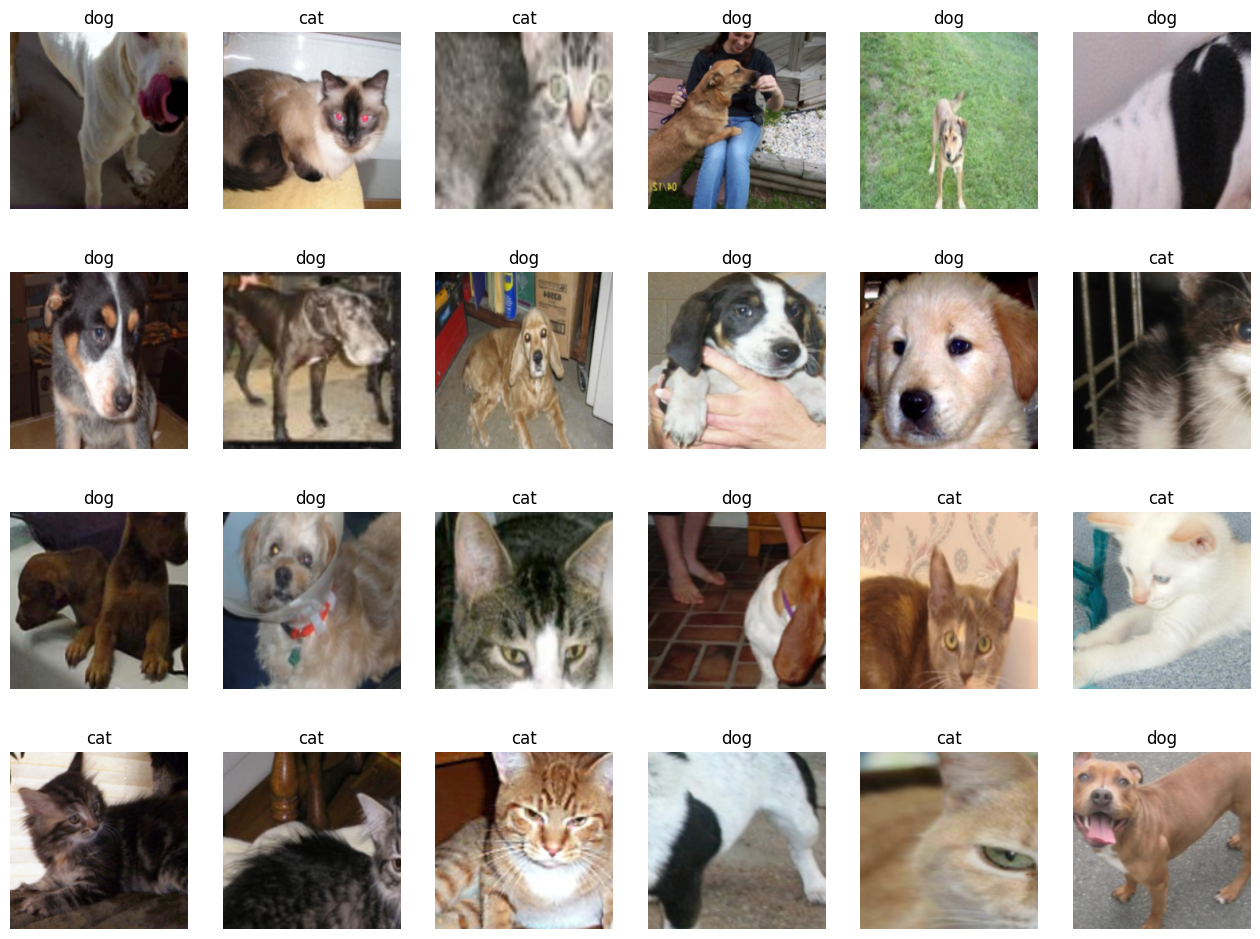

In [9]:
# 학습에 사용될 이미지 츨력
import numpy as np

samples, labels = next(iter(train_loader))
classes = {0:'cat', 1:'dog'}
fig = plt.figure(figsize=(16,24))
for i in range(24):
  a = fig.add_subplot(4, 6, i+1)
  a.set_title(classes[labels[i].item()]) # 레이블 정보를 함께 출력
  a.axis('off')
  a.imshow(np.transpose(samples[i].numpy(), (1,2,0)))
plt.subplots_adjust(bottom=0.2, top=0.6, hspace=0)

**사전 훈련된 모델 준비**

**ResNet18**
- ImageNet 데이터베이스의 영상 100만 개 이상으로 훈련된 합성곱 신경망. 전이 학습용 사전 훈련 모델을 제공함
- 단점: 입력 제약이 매우 크고, 메모리(RAM)가 충분하지 않으면 학습 속도가 느릴 수 있음
- 교재에는 ‘50개의 계층으로 구성'이라고 적혀 있지만, ResNet18은 이름처럼 18개 계층임 (50개 계층은 ResNet50)
- 자세한 내용은 6장에서 다룸

In [10]:
# 사전 훈련된 모델 내려받기
resnet18 = models.resnet18(pretrained=True)

/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:207: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:222: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


**사전 훈련된 모델 사용법**
- torchvision.models에서 resnet18, alexnet, vgg16, squeezenet, densenet, inception_v3, googlenet, shufflenet, mobilenet, resnext, wide_resnet, mnasnet 등을 불러올 수 있음
- 그냥 불러오면 **무작위 가중치**로 모델이 구성됨
- **pretrained=True**로 설정하면 사전 학습된 가중치를 사용함

In [11]:
# 사전 훈련된 모델의 파라미터 학습 유무 지정
def set_parameter_requires_grad(model, feature_extracting=True):
    if feature_extracting:
        for param in model.parameters():
            param.requires_grad = False
set_parameter_requires_grad(resnet18)

**합성곱층 가중치 고정**
- **requires_grad = False**: 역전파 중 해당 파라미터의 변화(기울기)를 계산할 필요가 없음을 나타냄
- 모델의 일부(합성곱층과 풀링층)는 고정하고 나머지만 학습하고 싶을 때 사용

**완전연결층 추가**
- ResNet18의 마지막 부분에 완전연결층을 새로 추가함 → 개와 고양이 두 클래스를 분류하는 용도
- 출력 크기 2는 클래스가 두 개라는 의미
- 새로 추가한 완전연결층의 파라미터는 weight와 bias
- named_parameters(): 모델에 접근해 파라미터 이름과 값을 가져올 때 사용

In [12]:
# ResNet18에 완전연결층 추가
resnet18.fc = nn.Linear(512,2) # 2는 클래스가 두 개라는 의미

In [13]:
# 모델의 파라미터 값 확인
for name, param in resnet18.named_parameters():
  if param.requires_grad:
    print(name, param.data)

fc.weight tensor([[ 0.0082, -0.0243,  0.0302,  ..., -0.0329, -0.0174,  0.0017],
        [-0.0059, -0.0195,  0.0042,  ...,  0.0188,  0.0174,  0.0164]])
fc.bias tensor([0.0117, 0.0160])


**모델 객체 생성과 손실 함수**
- 모델의 합성곱층 가중치는 고정(requires_grad=False)하고, 완전연결층만 학습(requires_grad=True)하도록 설정
- 옵티마이저: Adam(완전연결층의 파라미터만 전달)
- 손실 함수: CrossEntropyLoss
- ResNet18 구조: conv1 → bn1 → relu → maxpool → layer1~layer4(각각 BasicBlock 2개) → avgpool → fc(512 → 2)

In [14]:
# 모델 객체 생성 및 손실 함수 정의
model = models.resnet18(pretrained = True)

for param in model.parameters():
    param.requires_grad = False

model.fc = torch.nn.Linear(512, 2)
for param in model.fc.parameters():
    param.requires_grad = True

optimizer = torch.optim.Adam(model.fc.parameters())
cost = torch.nn.CrossEntropyLoss()
print(model)

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_sta

**모델 학습**

**학습 함수의 흐름**
- time.time(): 컴퓨터의 현재 시각을 구하는 함수로, 학습 시간을 계산하는 데 사용
- 에포크만큼 반복하며 다음을 수행함
    - 기울기를 0으로 초기화 → 순전파 → 손실 계산 → 역전파 → 가중치 업데이트
    - 출력과 레이블의 오차, 예측이 맞았는지 여부를 누적해 저장
- 에포크마다 평균 오차와 평균 정확도를 계산하고, 가장 높은 정확도(best_acc)를 기록함
- 에포크마다 모델의 가중치(state_dict)를 .pth 파일로 저장해 재사용할 수 있게 함
- 마지막에 정확도 기록과 오차 기록을 반환함

**학습할 파라미터를 옵티마이저에 전달**
- requires_grad가 True인 파라미터만 골라 옵티마이저에 전달함
- 전달되는 파라미터는 완전연결층의 fc.weight와 fc.bias뿐

**모델 학습**
- 학습 함수에 전달하는 것: 모델, 학습 데이터, 손실 함수, 옵티마이저, 장치(CPU 또는 GPU)
- 결과: 13에포크, 학습 시간 6분 27초, 최고 정확도 약 93% → 훈련 데이터로는 학습이 잘됨

In [18]:
# 모델 학습을 위한 함수 생성
def train_model(model, dataloaders, criterion, optimizer, device, num_epochs=13, is_train=True):
    since = time.time()
    acc_history = []
    loss_history = []
    best_acc = 0.0

    for epoch in range(num_epochs):
        print('Epoch {}/{}'.format(epoch, num_epochs - 1))
        print('-' * 10)

        running_loss = 0.0
        running_corrects = 0

        for inputs, labels in dataloaders:
            inputs = inputs.to(device)
            labels = labels.to(device)

            model.to(device)
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            _, preds = torch.max(outputs, 1)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * inputs.size(0)
            running_corrects += torch.sum(preds == labels.data)

        epoch_loss = running_loss / len(dataloaders.dataset)
        epoch_acc = running_corrects.double() / len(dataloaders.dataset)

        print('Loss: {:.4f} Acc: {:.4f}'.format(epoch_loss, epoch_acc))

        if epoch_acc > best_acc:
            best_acc = epoch_acc

        acc_history.append(epoch_acc.item())
        loss_history.append(epoch_loss)
        torch.save(model.state_dict(), os.path.join('../chap05/data/catanddog', '{0:0=2d}.pth'.format(epoch)))
        print()

    time_elapsed = time.time() - since
    print('Training complete in {:.0f}m {:.0f}s'.format(time_elapsed // 60, time_elapsed % 60))
    print('Best Acc: {:4f}'.format(best_acc))
    return acc_history, loss_history

In [19]:
# 파라미터 학습 결과를 옵티마이저에 전달
params_to_update = []
for name, param in resnet18.named_parameters():
  if param.requires_grad == True:
    params_to_update.append(param)
    print('\t', name)

optimizer = optim.Adam(params_to_update)

	 fc.weight
	 fc.bias


In [20]:
# 모델 학습
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
criterion = nn.CrossEntropyLoss()
train_acc_hist, train_loss_hist = train_model(resnet18, train_loader, criterion, optimizer, device)

Epoch 0/12
----------


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:437: UserWarning: This DataLoader will create 8 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


Loss: 0.4252 Acc: 0.7844

Epoch 1/12
----------
Loss: 0.3404 Acc: 0.8519

Epoch 2/12
----------
Loss: 0.2917 Acc: 0.8779

Epoch 3/12
----------
Loss: 0.3161 Acc: 0.8468

Epoch 4/12
----------
Loss: 0.2322 Acc: 0.9195

Epoch 5/12
----------
Loss: 0.2216 Acc: 0.9247

Epoch 6/12
----------
Loss: 0.2106 Acc: 0.9169

Epoch 7/12
----------
Loss: 0.2606 Acc: 0.8883

Epoch 8/12
----------
Loss: 0.3020 Acc: 0.8545

Epoch 9/12
----------
Loss: 0.2380 Acc: 0.8961

Epoch 10/12
----------
Loss: 0.2532 Acc: 0.8831

Epoch 11/12
----------
Loss: 0.1828 Acc: 0.9377

Epoch 12/12
----------
Loss: 0.1767 Acc: 0.9247

Training complete in 0m 36s
Best Acc: 0.937662


**테스트 데이터로 평가**

**테스트 데이터 전처리**
- Resize(224) → CenterCrop(224) → ToTensor
- 테스트 데이터는 데이터 확장(RandomResizedCrop, RandomHorizontalFlip)을 하지 않음
- 테스트 데이터 98개. 부족하지만 실습 환경을 고려해 일부만 사용

**평가 함수**
- glob: 현재 디렉터리에서 원하는 파일만 골라 가져올 때 사용. 학습 중 저장한 .pth 파일들을 불러옴
- 저장된 모델을 하나씩 불러와 테스트 데이터로 정확도를 측정함
- model.eval(): 모델을 평가 모드로 전환
- torch.no_grad(): 평가할 때는 autograd(기울기 계산)를 사용하지 않음
- **torch.max**: 텐서에서 최댓값이 들어 있는 인덱스를 반환함
    - 예) [0.2, 0.7, 0.8, 0.4]의 최댓값은 0.8이고 인덱스는 2 → 2를 반환
- preds.eq(labels): 예측과 정답이 일치하는지 검사함. 뒤의 .sum()은 일치한 개수의 합을 구함

**평가 결과**
- 최고 정확도 약 94.9%, 평가 시간 1분 52초
- 네트워크를 직접 구현하고 최적의 파라미터를 찾으려면 오래 걸리지만, 사전 훈련된 모델을 쓰면 쉽게 학습할 수 있어서 **실무에서도 많이 사용됨**

In [21]:
# 테스트 데이터 호출 및 전처리
test_path = '../chap05/data/catanddog/test'

transform = transforms.Compose(
    [
        transforms.Resize(224),
        transforms.CenterCrop(224),
        transforms.ToTensor(),
    ])
test_dataset = torchvision.datasets.ImageFolder(
    root=test_path,
    transform=transform
)
test_loader = torch.utils.data.DataLoader(
    test_dataset,
    batch_size=32,
    num_workers=1,
    shuffle=True
)
print(len(test_dataset))

98


In [22]:
# 테스트 데이터 평가 함수 생성
def eval_model(model, dataloaders, device):
  since = time.time()
  acc_history = []
  best_acc = 0.0

  saved_models = glob.glob('../chap05/data/catanddog/' + '*.pth')
  saved_models.sort()
  print('saved_model', saved_models)

  for model_path in saved_models:
    print('Loading model', model_path)

    model.load_state_dict(torch.load(model_path))
    model.eval()
    model.to(device)
    running_corrects = 0

    for inputs, labels in dataloaders:
      inputs = inputs.to(device)
      labels = labels.to(device)

      with torch.no_grad():
        outputs = model(inputs)

      _, preds = torch.max(outputs.data, 1)
      preds[preds >= 0.5] = 1
      preds[preds < 0.5] = 0
      running_corrects += preds.eq(labels).int().sum()

    epoch_acc = running_corrects.double() / len(dataloaders.dataset)
    print('Acc: {:.4f}'.format(epoch_acc))

    if epoch_acc > best_acc:
      best_acc = epoch_acc

    acc_history.append(epoch_acc.item())
    print()

  time_elapsed = time.time() - since
  print('Validation complete in {:.0f}m {:.0f}s'.format(time_elapsed // 60, time_elapsed % 60))
  print('Best Acc: {:4f}'.format(best_acc))

  return acc_history

In [23]:
# 테스트 데이터를 평가 함수에 적용
val_acc_hist = eval_model(resnet18, test_loader, device)

saved_model ['../chap05/data/catanddog/00.pth', '../chap05/data/catanddog/01.pth', '../chap05/data/catanddog/02.pth', '../chap05/data/catanddog/03.pth', '../chap05/data/catanddog/04.pth', '../chap05/data/catanddog/05.pth', '../chap05/data/catanddog/06.pth', '../chap05/data/catanddog/07.pth', '../chap05/data/catanddog/08.pth', '../chap05/data/catanddog/09.pth', '../chap05/data/catanddog/10.pth', '../chap05/data/catanddog/11.pth', '../chap05/data/catanddog/12.pth']
Loading model ../chap05/data/catanddog/00.pth
Acc: 0.8469

Loading model ../chap05/data/catanddog/01.pth
Acc: 0.9184

Loading model ../chap05/data/catanddog/02.pth
Acc: 0.9286

Loading model ../chap05/data/catanddog/03.pth
Acc: 0.9388

Loading model ../chap05/data/catanddog/04.pth
Acc: 0.9388

Loading model ../chap05/data/catanddog/05.pth
Acc: 0.9490

Loading model ../chap05/data/catanddog/06.pth
Acc: 0.9388

Loading model ../chap05/data/catanddog/07.pth
Acc: 0.9592

Loading model ../chap05/data/catanddog/08.pth
Acc: 0.9388

L

**학습 결과 시각화**

**정확도와 오차 그래프**
- 훈련·테스트 데이터 모두 에포크가 진행될수록 정확도가 높아지며 100%에 가까워짐. 에포크를 더 늘리면 100%에 더 수렴함
- 훈련 데이터의 오차는 에포크가 진행될수록 낮아짐 → 학습이 잘되었다고 볼 수 있음

**예측 이미지 출력용 전처리**
- tensor.clone(): 기존 텐서의 내용을 복사한 새 텐서를 만듦
- tensor.detach(): 기존 텐서에서 기울기가 전파되지 않는 텐서를 만듦
- tensor.clone().detach(): 기존 텐서를 복사한 새 텐서를 만들되, 기울기에는 영향을 주지 않음

| 구분 | 메모리 | 계산 그래프 상주 여부 |
|---|---|---|
| tensor.clone() | 새롭게 할당 | 계산 그래프에 계속 상주 |
| tensor.detach() | 공유해서 사용 | 계산 그래프에 상주하지 않음 |
| tensor.clone().detach() | 새롭게 할당 | 계산 그래프에 상주하지 않음 |


- **계산 그래프**: 계산 과정을 그래프로 나타낸 것. 여러 노드(node)와 노드를 연결하는 에지(edge)로 구성됨
    - 사용하는 이유 ① 국소적 계산이 가능함: 한 값이 바뀌면 나머지 계산 결과는 그대로 두고, 바뀐 값과 관련된 연산만 다시 계산하면 됨
    - 사용하는 이유 ② 역전파를 통한 미분 계산이 편리함: 연쇄 법칙으로 빠르고 간편하게 미분할 수 있음
- **연쇄 법칙(chain rule)**: 두 개 이상의 함수가 결합된 합성 함수의 미분법
    - 예) z = (x + y)²를 z = t²와 t = x + y의 합성 함수로 보고, 각 함수의 미분 결과를 곱함 → ∂z/∂x = 2t × 1 = 2(x + y)
- **clip()**: 입력값이 주어진 범위를 벗어나면 그 범위로 제한함
    - image.clip(0, 1): 이미지 데이터를 0과 1 사이 값으로 제한
    - 예) np.clip(exam, −0.5, 0.5) → −0.5보다 작은 값은 −0.5로, 0.5보다 큰 값은 0.5로 바뀜

**개와 고양이 예측 결과 출력**
- add_subplot: 한 화면에 여러 이미지를 담기 위해 사용
    - 첫 번째 파라미터: 행의 수(예: 2줄)
    - 두 번째 파라미터: 열의 수(예: 한 줄에 10개)
    - 세 번째 파라미터: 인덱스. 행과 열을 기준으로 순서대로 이미지를 출력함
    - xticks=[], yticks=[]: x축·y축의 틱(눈금)을 삭제함
- classes[preds[idx].item()]: 예측값이 0이면 고양이(cat), 1이면 개(dog)로 출력
- 제목은 '예측(정답)' 형식이며, 맞으면 초록색, 틀리면 빨간색으로 표시
- subplots_adjust: Figure 안에서 서브플롯의 위치(left, bottom, right, top)와 서브플롯 간 간격(hspace, wspace)을 조정함
- 결과 (p.228): 예측이 정확하지 않은 이미지도 있음 → 훈련 데이터를 늘리고 에포크 수도 늘리면 더 좋은 결과를 얻을 수 있음

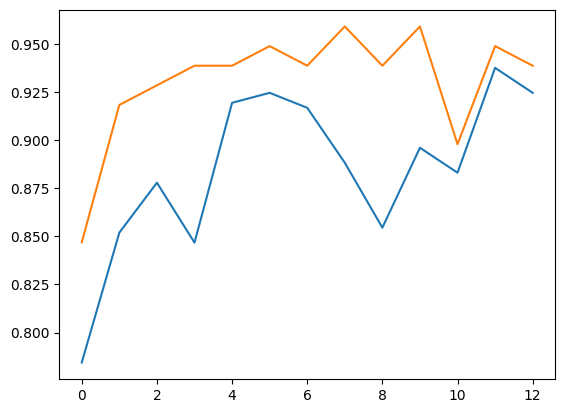

In [24]:
# 훈련과 테스트 데이터의 정확도를 그래프로 확인
plt.plot(train_acc_hist)
plt.plot(val_acc_hist)
plt.show()

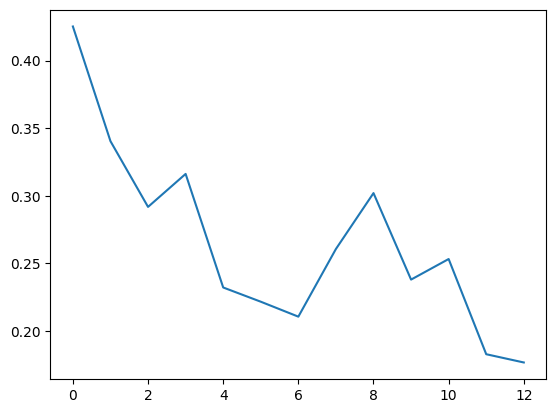

In [25]:
# 훈련 데이터의 오차에 대한 그래프 확인
plt.plot(train_loss_hist)
plt.show()

In [26]:
# 예측 이미지 출력을 위한 전처리 함수
def im_convert(tensor):
  image = tensor.clone().detach().numpy()
  image = image.transpose(1,2,0)
  image = image * (np.array((0.5,0.5,0.5)))
  image = image.clip(0,1)
  return image

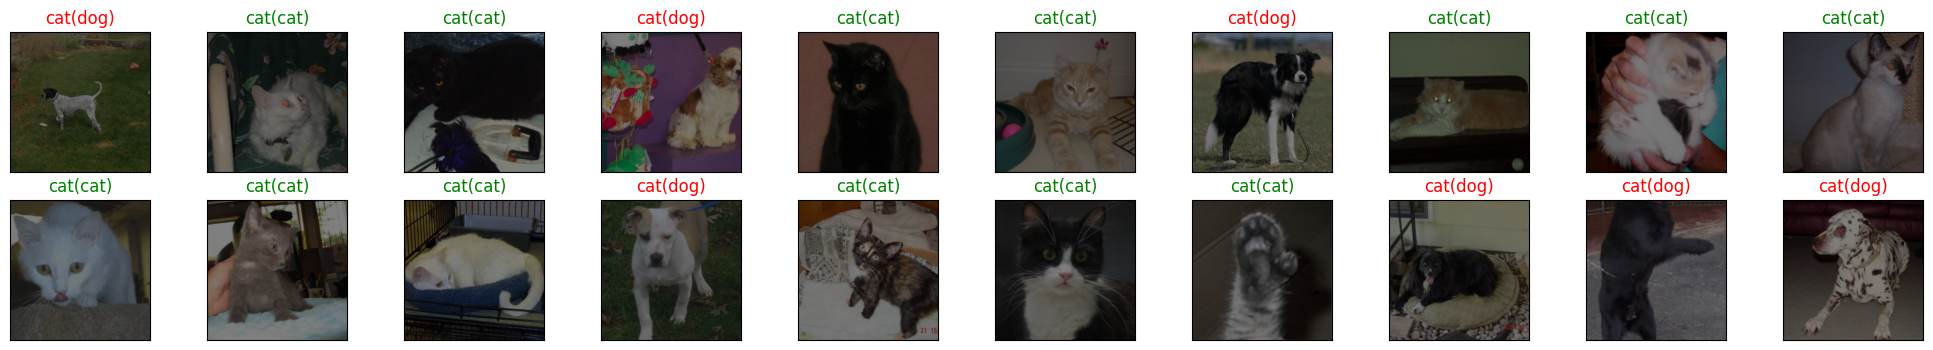

<Figure size 640x480 with 0 Axes>

In [27]:
# 개와 고양이 예측 결과 출력
classes = {0:'cat', 1:'dog'}

dataiter = iter(test_loader)
images, labels = next(dataiter)
output = model(images)
_, preds = torch.max(output, 1)

fig = plt.figure(figsize=(25,4))
for idx in np.arange(20):
  ax = fig.add_subplot(2, 10, idx+1, xticks=[], yticks=[])
  plt.imshow(im_convert(images[idx]))
  a.set_title(classes[labels[i].item()])
  ax.set_title('{}({})'.format(str(classes[preds[idx].item()]), str(classes[labels[idx].item()])), color=('green' if preds[idx]==labels[idx] else 'red'))
plt.show()
plt.subplots_adjust(bottom=0.2, top=0.6, hspace=0)

### **5.3.2 미세 조정 기법**
- **미세 조정(fine-tuning)**: 특성 추출 기법에서 더 나아가, 사전 훈련된 모델의 합성곱층과 데이터 분류기의 가중치까지 업데이트하며 훈련하는 방식
- 특성 추출은 목표 특성을 잘 추출했다는 전제에서만 좋은 성능을 냄
    - 특성이 잘못 추출되었다면(예: ImageNet 이미지와 전자상거래 상품 이미지의 특징이 다르다면), 새 이미지 데이터로 네트워크 가중치를 업데이트해 특성을 다시 추출할 수 있음
- 즉, 사전 학습된 모델을 목적에 맞게 재학습시키거나 학습된 가중치의 일부를 재학습시키는 것
- 분석하려는 데이터셋에 잘 맞도록 모델의 파라미터를 조정하는 기법
- 미세 조정 과정에는 연산량이 많으므로 **CPU보다 GPU 사용을 권장**함

**데이터셋 크기와 유사성에 따른 전략**

| 상황 | 학습할 부분 | 이유 |
|---|---|---|
| 데이터셋이 크고 유사성이 작음 | 모델 전체를 재학습 | 데이터셋이 크므로 전체를 재학습하는 것이 좋음 |
| 데이터셋이 크고 유사성이 큼 | 합성곱층의 뒷부분(완전연결층과 가까운 부분) + 데이터 분류기 | 데이터가 유사하므로 강한 특징이 나타나는 뒷부분과 분류기만 학습해도 최적의 성능을 냄 |
| 데이터셋이 작고 유사성이 작음 | 합성곱층의 일부분 + 데이터 분류기 | 데이터가 적어 일부 계층에만 적용하면 효과가 없을 수 있으므로, 합성곱층을 어디까지 학습할지 적당히 정해야 함 |
| 데이터셋이 작고 유사성이 큼 | 데이터 분류기(완전연결층)만 학습 | 데이터가 적은데 많은 계층을 학습하면 과적합이 생길 수 있음 |

* 파라미터를 업데이트할 때 큰 변화를 주면 과적합이 생길 수 있으므로, **정교하고 미세한 파라미터 업데이트**가 필요함

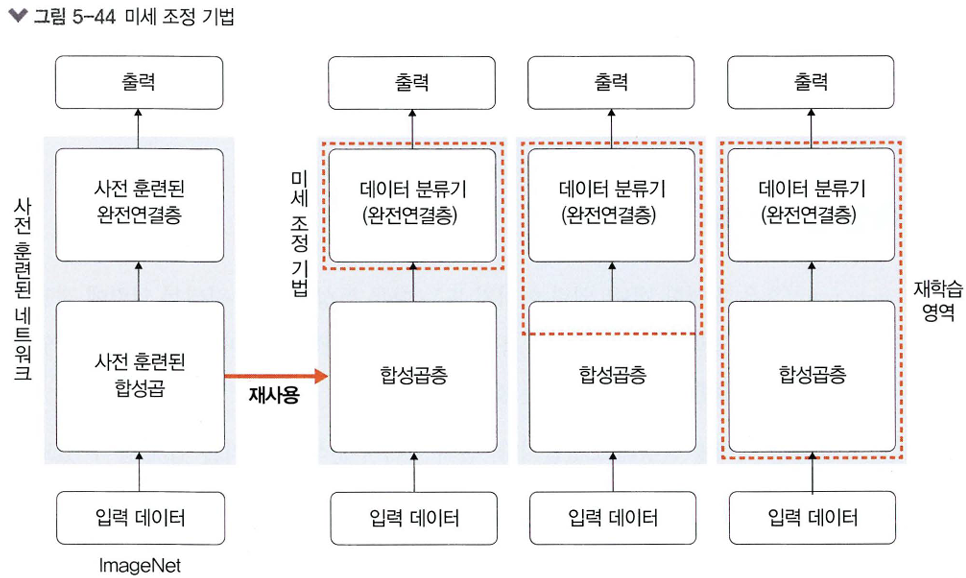